# UFC Fight Outcome Prediction

**Author:** Maksym Redchenko · **Student number:** C00302240
**Module:** Data Science & Machine Learning 1, Continuous Assessment Portfolio, Project 2
**GitHub:** https://github.com/S5in/Data-Science-and-Machine-Learning

This notebook asks whether the winner of a UFC fight can be predicted from information that was available **before** the fight. It follows the CRISP-DM process from the lectures. This first part covers business understanding, building a relational database for the data, data understanding and data quality. Feature engineering and modelling follow in the next part.

1. Business understanding
2. Setup
3. Data infrastructure: building the SQLite database
4. Data understanding
5. Data quality summary
6. Provenance, licence and ethics
7. Plan for feature engineering and modelling

In [1]:
# Author: Maksym Redchenko
# Student number: C00302240
# Project 2: UFC Fight Outcome Prediction (Data Science & ML 1 CA portfolio)

## 1. Business understanding

**Question.** Can engineered features built only from information known before a fight predict its winner better than a simple baseline?

**Why it matters.** Fight prediction is used by analysts, broadcasters, fans and the betting industry. It is also a good data science problem, because the obvious data is full of traps. The main one is **data leakage**: accidentally using information from after the fight to predict it, which makes a model look far better than it really is.

**Type of analytics.** This is **predictive** analytics (will fighter A beat fighter B?), supported by **descriptive** analytics in Section 4 (how have UFC fights changed over 30 years?).

**Success criteria.** The final model is trained on older fights and tested on the most recent ones, with no shuffling. It is judged by:

- **Accuracy** compared with a naive baseline (Section 4.6 shows why choosing this baseline is less obvious than it sounds), and
- **Log loss**, which also rewards well-calibrated probabilities (a model that says 90% should be right about 90% of the time).

## 2. Setup

In [2]:
import re
import sqlite3
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --- Data locations ------------------------------------------------------
DATA_ZIP = Path("..") / "ufc_archive.zip"   # raw CSVs scraped from ufcstats.com
DB_PATH = Path("ufc.db")                    # SQLite database built by this notebook

# --- Dates that matter (explained in Section 4) ---------------------------
CORNER_RELIABLE_FROM = "2010-04-01"  # before this, the winner is always listed as 'red'

# --- Plot style -----------------------------------------------------------
plt.rcParams.update({
    "figure.figsize": (11, 4.5),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

## 3. Data infrastructure: building the SQLite database

### 3.1 The raw data

The data was scraped from **ufcstats.com**, the UFC's official statistics site. It arrives as a zip of CSV files, one per table.

In [3]:
with zipfile.ZipFile(DATA_ZIP) as archive:
    files = pd.DataFrame([{"file": i.filename, "size (KB)": round(i.file_size / 1024)}
                          for i in archive.infolist()])
files

,file,size (KB)
0,event.csv,92
1,fight.csv,2186
2,fighter.csv,444
3,fighter_bonus.csv,97
4,master.csv,6145
5,round.csv,3916
6,scrape_error.csv,79


In [4]:
def read_csv_from_zip(name):
    """Read one CSV file from the UFC zip archive."""
    with zipfile.ZipFile(DATA_ZIP) as archive, archive.open(name) as csv_file:
        return pd.read_csv(csv_file, low_memory=False)


raw = {name: read_csv_from_zip(f"{name}.csv")
       for name in ["event", "fight", "fighter", "round", "fighter_bonus", "scrape_error", "master"]}
pd.DataFrame({"rows": {k: len(v) for k, v in raw.items()},
              "columns": {k: v.shape[1] for k, v in raw.items()}})

,rows,columns
event,1259,4
fight,11441,14
fighter,4581,16
round,25131,48
fighter_bonus,2409,2
scrape_error,330,9
master,11441,93


### 3.2 Why a relational database?

The data is **structured** and **relational**: every table has an ID column, and the tables refer to each other through those IDs (a fight belongs to an event, has two fighters and is made of rounds). This is the relational model from the Data Modelling lecture, so a relational database is a natural fit.

**SQLite** was chosen because:

- It is built into Python (`sqlite3`), so there is nothing to install or run, and the whole database is a single file.
- It supports SQL, so the data can be explored and joined with standard queries. Feature engineering in the next part will use these joins.
- It enforces **primary keys**, **foreign keys** and **constraints**, which catch data errors during loading.
- It provides **ACID** transactions (Data Modelling lecture), so a failed load can't leave the database half-written.

A NoSQL database (document, key-value or graph store) would suit unstructured data or very large distributed systems. Neither applies here: the data has a fixed schema and is small (about 20 MB), so a relational database is simpler and safer.

**`master.csv` is not loaded.** It is a denormalised copy of the other tables joined together (93 columns), which repeats every fighter's details on every fight. Section 4.8 shows that it also fills missing statistics with zeros. The database stores the normalised tables instead, and any combined view can be rebuilt with a SQL join.

### 3.3 The schema

```
event (1) ──< fight (many) >── fighter      each fight has a red and a blue fighter
                │
                ├──< round          one row per round (fight_id, round_no)
                └──< fight_bonus    performance bonuses awarded for the fight
```

### 3.4 Transforming the data before loading (ETL)

Some columns are stored as text that can't be used in calculations. They are converted while loading, so the database holds clean, typed values:

| Raw value | Converted to |
|---|---|
| Height `5' 10"` | `height_cm` = 177.8 |
| Weight in lbs, reach in inches | `weight_kg`, `reach_cm` |
| Fight end time `2:04` and round 3 | `finish_time_s` = 124 and `duration_s`, the total fight time in seconds |
| Time format `3 Rnd (5-5-5)` | `scheduled_rounds` = 3 |
| Control time `1:00` | `ctrl_s` = 60 |

In [5]:
def mmss_to_seconds(value):
    """Convert 'm:ss' text to seconds. Missing values stay missing."""
    if pd.isna(value):
        return np.nan
    minutes, seconds = str(value).split(":")
    return int(minutes) * 60 + int(seconds)


def height_to_cm(value):
    """Convert a height like 5' 10\" to centimetres."""
    if pd.isna(value):
        return np.nan
    feet, inches = map(int, re.findall(r"\d+", value))
    return round((feet * 12 + inches) * 2.54, 1)


def round_lengths(time_format):
    """Round lengths in minutes from a format like '3 Rnd (5-5-5)'. Empty if unknown."""
    inside = re.search(r"\(([\d-]+)\)", str(time_format))
    return [int(x) for x in inside.group(1).split("-")] if inside else []


def fight_duration(row):
    """Total time fought in seconds: full earlier rounds plus the time in the final round."""
    lengths = round_lengths(row["time_format"])
    finished_rounds = row["round"] - 1
    if finished_rounds > len(lengths):
        return np.nan               # format doesn't say how long the earlier rounds were
    return sum(lengths[:finished_rounds]) * 60 + mmss_to_seconds(row["time"])

In [6]:
def transform_event(df):
    return df.rename(columns={"date": "event_date"})


def transform_fighter(df):
    out = df.rename(columns={"fighter_name": "name", "fighter_nick_name": "nickname"})
    out["height_cm"] = out["height"].apply(height_to_cm)
    out["weight_kg"] = (out["weight_lbs"] * 0.4536).round(1)
    out["reach_cm"] = (out["reach_inches"] * 2.54).round(1)
    return out.drop(columns=["height", "weight_lbs", "reach_inches"])


def transform_fight(df):
    out = df.rename(columns={"round": "finish_round"})
    out["finish_time_s"] = df["time"].apply(mmss_to_seconds)
    out["duration_s"] = df.apply(fight_duration, axis=1)
    out["scheduled_rounds"] = df["time_format"].str.extract(r"^(\d+) Rnd", expand=False).astype(float)
    return out.drop(columns=["time"])


def transform_round(df):
    out = df.copy()
    out["r_ctrl_s"] = df["r_ctrl"].apply(mmss_to_seconds)
    out["b_ctrl_s"] = df["b_ctrl"].apply(mmss_to_seconds)
    return out.drop(columns=["r_ctrl", "b_ctrl"])


clean = {
    "event": transform_event(raw["event"]),
    "fighter": transform_fighter(raw["fighter"]),
    "fight": transform_fight(raw["fight"]),
    "round": transform_round(raw["round"]),
    "fight_bonus": raw["fighter_bonus"],
    "scrape_error": raw["scrape_error"],
}
clean["fight"][["time_format", "finish_round", "finish_time_s", "duration_s", "scheduled_rounds"]].head()

,time_format,finish_round,finish_time_s,duration_s,scheduled_rounds
0,3 Rnd (5-5-5),2,71,371.0,3.0
1,3 Rnd (5-5-5),3,124,724.0,3.0
2,3 Rnd (5-5-5),1,87,87.0,3.0
3,1 Rnd + OT (12-3),1,623,623.0,1.0
4,1 Rnd + 2OT (15-3-3),1,16,16.0,1.0


### 3.5 Creating the tables

The `CREATE TABLE` statements are generated from each DataFrame's columns, adding the keys and constraints from the schema. Writing them out by hand for the 48-column `round` table would be long and error-prone.

In [7]:
SQL_TYPES = {"int64": "INTEGER", "float64": "REAL", "bool": "INTEGER"}

TABLE_DESIGN = {
    "event": {"primary_key": ["event_id"], "foreign_keys": {}, "not_null": ["event_name", "event_date"]},
    "fighter": {"primary_key": ["fighter_id"], "foreign_keys": {}, "not_null": ["name"]},
    "fight": {
        "primary_key": ["fight_id"],
        "foreign_keys": {"event_id": "event", "r_id": "fighter", "b_id": "fighter", "winner_id": "fighter"},
        "not_null": ["event_id", "r_id", "b_id", "result_status"],
        "checks": ["result_status IN ('win', 'draw', 'no_contest')",
                   "winner_id IS NULL OR winner_id IN (r_id, b_id)"],
    },
    "round": {"primary_key": ["fight_id", "round_no"], "foreign_keys": {"fight_id": "fight"}, "not_null": []},
    "fight_bonus": {"primary_key": ["fight_id", "bonus_type"], "foreign_keys": {"fight_id": "fight"}, "not_null": []},
    "scrape_error": {"primary_key": ["error_id"], "foreign_keys": {}, "not_null": []},
}


def create_table_sql(name, df, design):
    """Build a CREATE TABLE statement with types, keys and constraints."""
    lines = []
    for column, dtype in df.dtypes.items():
        sql_type = SQL_TYPES.get(str(dtype), "TEXT")
        not_null = " NOT NULL" if column in design["not_null"] else ""
        lines.append(f"    {column} {sql_type}{not_null}")
    lines.append(f"    PRIMARY KEY ({', '.join(design['primary_key'])})")
    for column, parent in design["foreign_keys"].items():
        parent_key = TABLE_DESIGN[parent]["primary_key"][0]
        lines.append(f"    FOREIGN KEY ({column}) REFERENCES {parent}({parent_key})")
    for check in design.get("checks", []):
        lines.append(f"    CHECK ({check})")
    return f"CREATE TABLE {name} (\n" + ",\n".join(lines) + "\n)"


print(create_table_sql("fight", clean["fight"], TABLE_DESIGN["fight"]))

CREATE TABLE fight (
    event_id TEXT NOT NULL,
    fight_id TEXT,
    weight_class TEXT,
    title_fight INTEGER,
    r_id TEXT NOT NULL,
    b_id TEXT NOT NULL,
    winner_id TEXT,
    result_status TEXT NOT NULL,
    method TEXT,
    finish_round INTEGER,
    time_format TEXT,
    referee TEXT,
    details TEXT,
    finish_time_s INTEGER,
    duration_s REAL,
    scheduled_rounds REAL,
    PRIMARY KEY (fight_id),
    FOREIGN KEY (event_id) REFERENCES event(event_id),
    FOREIGN KEY (r_id) REFERENCES fighter(fighter_id),
    FOREIGN KEY (b_id) REFERENCES fighter(fighter_id),
    FOREIGN KEY (winner_id) REFERENCES fighter(fighter_id),
    CHECK (result_status IN ('win', 'draw', 'no_contest')),
    CHECK (winner_id IS NULL OR winner_id IN (r_id, b_id))
)


In [8]:
def build_database(db_path, tables):
    """Create a fresh SQLite database, create every table, load the data and add indexes."""
    if db_path.exists():
        db_path.unlink()
    conn = sqlite3.connect(db_path)
    conn.execute("PRAGMA foreign_keys = ON")
    with conn:  # one transaction: either everything loads or nothing does
        for name in ["event", "fighter", "fight", "round", "fight_bonus", "scrape_error"]:
            conn.execute(create_table_sql(name, tables[name], TABLE_DESIGN[name]))
            tables[name].to_sql(name, conn, if_exists="append", index=False)
        conn.execute("CREATE INDEX idx_fight_event ON fight(event_id)")
        conn.execute("CREATE INDEX idx_fight_red ON fight(r_id)")
        conn.execute("CREATE INDEX idx_fight_blue ON fight(b_id)")
    return conn


conn = build_database(DB_PATH, clean)
print(f"Database written to {DB_PATH} ({DB_PATH.stat().st_size / 1e6:.1f} MB)")

Database written to ufc.db (8.7 MB)


### 3.6 Verifying the load

In [9]:
def query(sql, params=()):
    """Run a SQL query against the UFC database and return a DataFrame."""
    return pd.read_sql_query(sql, conn, params=params)


checks = pd.DataFrame({
    "rows in CSV": {name: len(df) for name, df in clean.items()},
    "rows in database": {name: query(f"SELECT COUNT(*) AS n FROM {name}")["n"][0] for name in clean},
})
checks["match"] = checks["rows in CSV"] == checks["rows in database"]
print("Foreign-key violations:", len(query("PRAGMA foreign_key_check")))
checks

Foreign-key violations: 0


,rows in CSV,rows in database,match
event,1259,1259,True
fighter,4581,4581,True
fight,11441,11441,True
round,25131,25131,True
fight_bonus,2409,2409,True
scrape_error,330,330,True


Every row loaded, and SQLite found **no foreign-key violations**. Every fight points to a real event, every fighter ID in a fight exists, and every round and bonus belongs to a real fight. The `CHECK` constraints also confirm that every winner is one of the two fighters in their fight.

## 4. Data understanding

From here on, the data is explored with **SQL queries** against the database.

### 4.1 Overview

In [10]:
query("""
    SELECT COUNT(*)                            AS fights,
           COUNT(DISTINCT f.event_id)          AS events,
           (SELECT COUNT(*) FROM fighter)      AS fighters,
           MIN(e.event_date)                   AS first_event,
           MAX(e.event_date)                   AS last_event,
           SUM(f.title_fight)                  AS title_fights
    FROM fight f
    JOIN event e ON e.event_id = f.event_id
""")

,fights,events,fighters,first_event,last_event,title_fights
0,11441,1259,4581,1993-11-12,2026-08-08,623


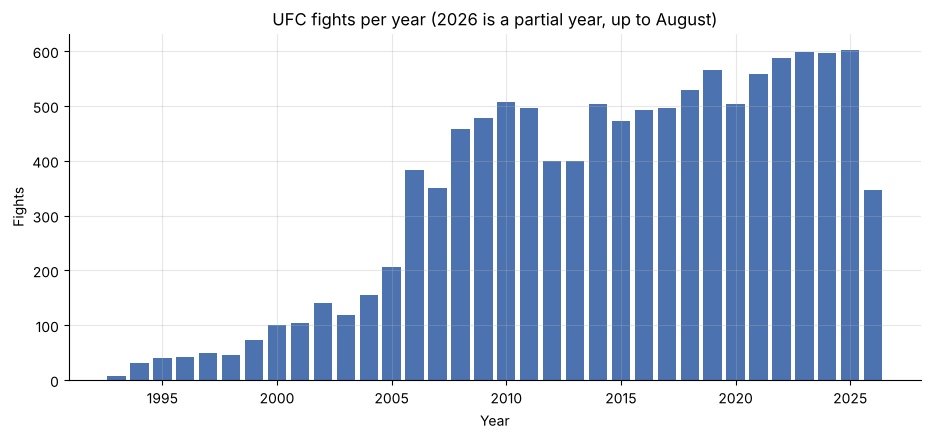

In [11]:
fights_per_year = query("""
    SELECT CAST(strftime('%Y', e.event_date) AS INTEGER) AS year, COUNT(*) AS fights
    FROM fight f JOIN event e ON e.event_id = f.event_id
    GROUP BY year ORDER BY year
""")

fig, ax = plt.subplots()
ax.bar(fights_per_year["year"], fights_per_year["fights"], color="#4C72B0")
ax.set_title("UFC fights per year (2026 is a partial year, up to August)")
ax.set_xlabel("Year")
ax.set_ylabel("Fights")
plt.show()

**Observation.** The UFC held only a few dozen fights a year in the 1990s. Numbers grew quickly from 2005 and have been at roughly 500–600 a year since the mid-2010s. Most of the data comes from the modern era, which is the era the model needs to predict.

### 4.2 How fights end

In [12]:
query("""
    SELECT result_status, COUNT(*) AS fights,
           ROUND(100.0 * COUNT(*) / (SELECT COUNT(*) FROM fight), 1) AS pct
    FROM fight GROUP BY result_status ORDER BY fights DESC
""")

,result_status,fights,pct
0,win,11238,98.2
1,no_contest,118,1.0
2,draw,85,0.7


In [13]:
query("""
    SELECT method, COUNT(*) AS fights,
           ROUND(100.0 * COUNT(*) / (SELECT COUNT(*) FROM fight), 1) AS pct
    FROM fight GROUP BY method ORDER BY fights DESC
""")

,method,fights,pct
0,Decision - Unanimous,3860,33.7
1,KO/TKO,3715,32.5
2,Submission,2411,21.1
3,Decision - Split,1015,8.9
4,TKO - Doctor's Stoppage,152,1.3
5,Decision - Majority,117,1.0
6,Overturned,71,0.6
7,Could Not Continue,48,0.4
8,DQ,35,0.3
9,Other,14,0.1


**Observation.** 98% of fights have a winner. Draws and no-contests (fights that were overturned or stopped without a result, about 1.8% together) can't be used to train a winner-prediction model, so they will be excluded from the target. Among wins, decisions (judges' scores) are the most common outcome, followed by knockouts (KO/TKO) and submissions.

### 4.3 The changing sport: finish rate over time

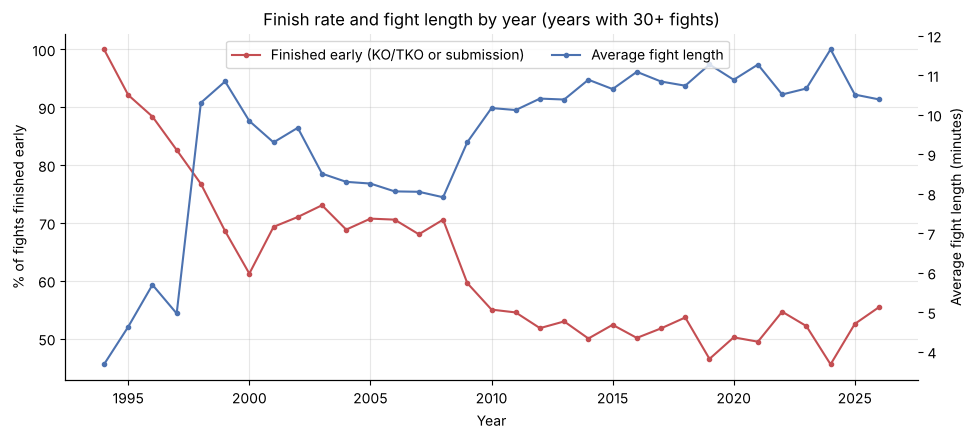

In [14]:
finish_rate = query("""
    SELECT CAST(strftime('%Y', e.event_date) AS INTEGER) AS year,
           AVG(CASE WHEN f.method IN ('KO/TKO', 'Submission', 'TKO - Doctor''s Stoppage')
                    THEN 1.0 ELSE 0.0 END) AS finish_rate,
           AVG(f.duration_s) / 60.0 AS avg_minutes
    FROM fight f JOIN event e ON e.event_id = f.event_id
    WHERE f.result_status = 'win'
    GROUP BY year HAVING COUNT(*) >= 30
    ORDER BY year
""")

fig, ax1 = plt.subplots()
ax1.plot(finish_rate["year"], finish_rate["finish_rate"] * 100, color="#C44E52", marker="o", markersize=3,
         label="Finished early (KO/TKO or submission)")
ax1.set_ylabel("% of fights finished early")
ax1.set_xlabel("Year")
ax2 = ax1.twinx()
ax2.plot(finish_rate["year"], finish_rate["avg_minutes"], color="#4C72B0", marker="o", markersize=3,
         label="Average fight length")
ax2.set_ylabel("Average fight length (minutes)")
ax2.grid(False)
fig.legend(loc="upper center", bbox_to_anchor=(0.5, 0.88), ncol=2)
ax1.set_title("Finish rate and fight length by year (years with 30+ fights)")
plt.show()

**Observation.** The sport has changed a lot. In the mid-1990s almost every fight was finished early. From about 2000 to 2008, around 70% were, and since 2010 only about half have been. The biggest drop came between 2008 and 2010. Over the same period, average fight length more than doubled, from about 4–5 minutes in the mid-1990s to 10–11 minutes today, as more fights went the full distance to a judges' decision. (Early events also used different rules and round formats.) A model trained on early fights would learn patterns that no longer apply, which is another reason to train and test on modern fights.

### 4.4 Weight classes

In [15]:
weight_classes = query("""
    SELECT weight_class, COUNT(*) AS fights FROM fight
    GROUP BY weight_class ORDER BY fights DESC
""")
print(f"{len(weight_classes)} different weight-class labels")
print(f"Top 15 labels cover {weight_classes['fights'].head(15).sum() / weight_classes['fights'].sum():.1%} of fights")
weight_classes.head(15)

154 different weight-class labels
Top 15 labels cover 97.9% of fights


,weight_class,fights
0,Lightweight,1830
1,Welterweight,1693
2,Middleweight,1523
3,Featherweight,1101
4,Heavyweight,1087
5,Bantamweight,963
6,Light Heavyweight,938
7,Flyweight,495
8,Women's Strawweight,408
9,Open Weight,317


**Observation.** The `weight_class` field is messy. It contains the standard divisions (Lightweight, Welterweight and so on), but also labels like tournament names (*Ultimate Fighter 9 Welterweight Tournament*) and other promotions' titles (*WEC*, *Strikeforce*, *Pride*). The 15 most common labels cover almost all fights. The rest will be mapped to standard divisions by keyword in the feature-engineering part (for example, anything containing *Welterweight* becomes Welterweight).

### 4.5 Fighters

Fighters who appear in at least one fight: 4,124
Median UFC fights per fighter: 3 (maximum 50)
Fighters with only one UFC fight: 31%


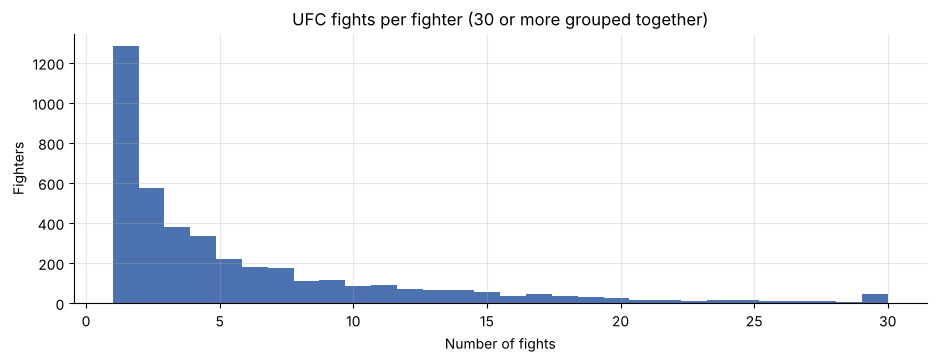

In [16]:
fights_per_fighter = query("""
    SELECT fighter_id, COUNT(*) AS fights FROM (
        SELECT r_id AS fighter_id FROM fight
        UNION ALL
        SELECT b_id AS fighter_id FROM fight
    ) GROUP BY fighter_id
""")["fights"]

print(f"Fighters who appear in at least one fight: {len(fights_per_fighter):,}")
print(f"Median UFC fights per fighter: {fights_per_fighter.median():.0f} (maximum {fights_per_fighter.max()})")
print(f"Fighters with only one UFC fight: {(fights_per_fighter == 1).mean():.0%}")

fig, ax = plt.subplots(figsize=(11, 3.5))
ax.hist(fights_per_fighter.clip(upper=30), bins=30, color="#4C72B0")
ax.set_title("UFC fights per fighter (30 or more grouped together)")
ax.set_xlabel("Number of fights")
ax.set_ylabel("Fighters")
plt.show()

In [17]:
fighter_missing = query("""
    SELECT COUNT(*) AS fighters,
           ROUND(100.0 * SUM(height_cm IS NULL) / COUNT(*), 1) AS pct_no_height,
           ROUND(100.0 * SUM(reach_cm IS NULL) / COUNT(*), 1)  AS pct_no_reach,
           ROUND(100.0 * SUM(dob IS NULL) / COUNT(*), 1)       AS pct_no_dob,
           ROUND(100.0 * SUM(stance IS NULL) / COUNT(*), 1)    AS pct_no_stance,
           SUM(slpm = 0 AND str_acc = 0 AND sapm = 0 AND str_def = 0
               AND td_avg = 0 AND td_acc = 0 AND td_def = 0 AND sub_avg = 0) AS all_stats_zero
    FROM fighter
""")
fighter_missing

,fighters,pct_no_height,pct_no_reach,pct_no_dob,pct_no_stance,all_stats_zero
0,4581,8.1,43.5,11.1,19.6,754


**Observation.** Fighter histories are short. The median fighter has only a few UFC fights, and almost a third have just one. Many fights will therefore involve at least one fighter with little or no UFC history, and the features in the next part must handle this (for example a "number of previous fights" feature, and sensible default values for debuts).

Physical details are often missing, especially **reach**, and some fighters have **every statistic set to exactly 0**. That isn't a real value, it's a placeholder for fighters with no recorded statistics, so it must be treated as missing.

### 4.6 The red-corner problem

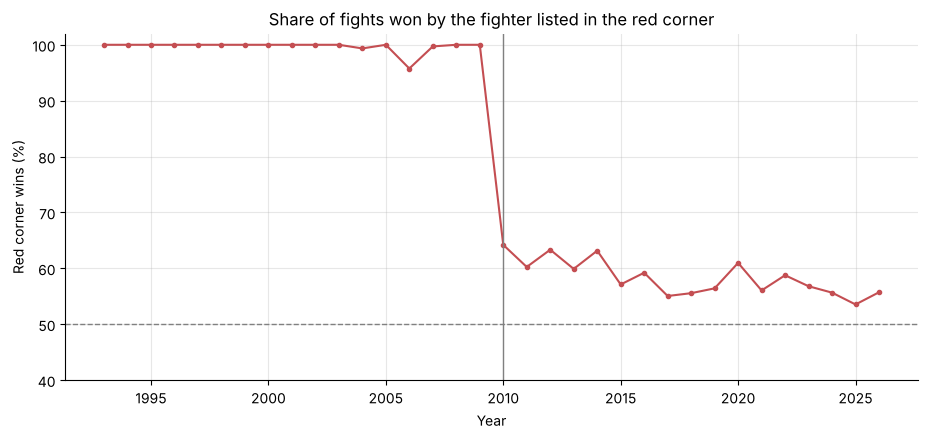

,red_win_rate,fights
year,,
2006,95.8%,377
2007,99.7%,344
2008,100.0%,455
2009,100.0%,475
2010,64.2%,500
2011,60.2%,488
2012,63.3%,390
2013,59.9%,389


In [18]:
red_wins = query("""
    SELECT CAST(strftime('%Y', e.event_date) AS INTEGER) AS year,
           AVG(CASE WHEN f.winner_id = f.r_id THEN 1.0 ELSE 0.0 END) AS red_win_rate,
           COUNT(*) AS fights
    FROM fight f JOIN event e ON e.event_id = f.event_id
    WHERE f.result_status = 'win'
    GROUP BY year ORDER BY year
""")

fig, ax = plt.subplots()
ax.plot(red_wins["year"], red_wins["red_win_rate"] * 100, color="#C44E52", marker="o", markersize=3)
ax.axhline(50, color="grey", linewidth=1, linestyle="--")
ax.axvline(2010, color="grey", linewidth=1)
ax.set_ylim(40, 102)
ax.set_title("Share of fights won by the fighter listed in the red corner")
ax.set_xlabel("Year")
ax.set_ylabel("Red corner wins (%)")
plt.show()

red_wins[(red_wins["year"] >= 2006) & (red_wins["year"] <= 2013)].set_index("year").style.format(
    {"red_win_rate": "{:.1%}"})

In [19]:
quarterly = query("""
    SELECT strftime('%Y', e.event_date) || '-Q' || ((CAST(strftime('%m', e.event_date) AS INTEGER) + 2) / 3) AS quarter,
           AVG(CASE WHEN f.winner_id = f.r_id THEN 1.0 ELSE 0.0 END) AS red_win_rate,
           COUNT(*) AS fights
    FROM fight f JOIN event e ON e.event_id = f.event_id
    WHERE f.result_status = 'win' AND e.event_date BETWEEN '2009-07-01' AND '2010-12-31'
    GROUP BY quarter ORDER BY quarter
""")
quarterly.style.format({"red_win_rate": "{:.1%}"})

,quarter,red_win_rate,fights
0,2009-Q3,100.0%,96
1,2009-Q4,100.0%,149
2,2010-Q1,90.2%,122
3,2010-Q2,52.4%,124
4,2010-Q3,62.4%,125
5,2010-Q4,52.7%,129


**Observation: an important data quality problem.** Up to the end of 2009, the fighter in the "red" column wins **almost every fight**. That isn't a real effect. In older records, ufcstats.com lists the **winner first**, and the scraper stored the first fighter as red. From around **April 2010** the red corner wins about 52–65% of fights, which is realistic (in the UFC the red corner usually goes to the favourite or the champion).

**Why this matters for the model.** If the model were given "which column is this fighter in?", it would learn "red wins" from the old fights. That would make it look very accurate on historical data while being useless for real predictions. This is a form of **data leakage**. To avoid it:

1. The model will not use corner colour from fights before April 2010 (`CORNER_RELIABLE_FROM`).
2. The fighters in each fight will be put in a **random order** (fighter A / fighter B) before modelling, so the column a fighter is in carries no information.
3. Fights before 2010 are still useful for building each fighter's **history** (record, Elo rating), because who won those fights is correct. Only the corner colour is unreliable.

### 4.7 Fight statistics: the leakage trap

In [20]:
example = query("""
    SELECT fr.name, COUNT(*) AS ufc_fights,
           MIN(e.event_date) AS first_fight, MAX(e.event_date) AS last_fight,
           fr.slpm AS strikes_landed_per_min, fr.str_acc AS striking_accuracy_pct
    FROM fighter fr
    JOIN fight f ON fr.fighter_id IN (f.r_id, f.b_id)
    JOIN event e ON e.event_id = f.event_id
    GROUP BY fr.fighter_id
    ORDER BY ufc_fights DESC
    LIMIT 5
""")
example

,name,ufc_fights,first_fight,last_fight,strikes_landed_per_min,striking_accuracy_pct
0,Alistair Overeem,50,2002-07-20,2021-02-06,3.67,64
1,Andrei Arlovski,48,2000-11-17,2024-06-29,3.82,45
2,Donald Cerrone,48,2007-09-05,2022-07-02,4.41,46
3,Jim Miller,47,2008-10-18,2026-05-09,2.92,42
4,Kazushi Sakuraba,44,1997-12-21,2011-09-24,1.26,41


**Observation.** The `fighter` table has **one row per fighter**, and the career statistics (strikes landed per minute, accuracy, takedowns and so on) were captured when the data was scraped in August 2026. For example, Alistair Overeem's figures cover all 50 of his fights from 2002 to 2021, including the ones a model would be asked to predict.

Using them to predict his 2012 fight would give the model information from 2013–2021. This is the main leakage trap in this dataset. In the next part, all fighter statistics will instead be **rebuilt from the `round` table using only fights that happened before the fight being predicted**.

### 4.8 Missing round statistics

In [21]:
missing_rounds = query("""
    SELECT CAST(strftime('%Y', e.event_date) AS INTEGER) AS year, COUNT(*) AS fights_without_round_stats
    FROM fight f JOIN event e ON e.event_id = f.event_id
    WHERE f.fight_id NOT IN (SELECT DISTINCT fight_id FROM round)
    GROUP BY year ORDER BY year
""")
print(f"Fights with no round statistics: {missing_rounds['fights_without_round_stats'].sum()}")
print("All of them are listed in scrape_error:",
      query("SELECT COUNT(*) AS n FROM fight WHERE fight_id NOT IN (SELECT fight_id FROM round) "
            "AND fight_id NOT IN (SELECT entity_id FROM scrape_error)")["n"][0] == 0)
missing_rounds.set_index("year").T

Fights with no round statistics: 330
All of them are listed in scrape_error: True


year,1994,1995,1996,1997,1998,2001,2002,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013
fights_without_round_stats,2,6,7,2,4,8,17,1,1,18,22,43,63,60,73,1,2


In [22]:
master_zeroes = raw["master"].loc[
    ~raw["master"]["fight_id"].isin(raw["round"]["fight_id"]),
    ["r_total_sig_landed", "b_total_sig_landed", "r_total_ctrl_seconds"]
]
print("In master.csv, the same fights have these 'totals':")
master_zeroes.describe().loc[["count", "mean", "max"]]

In master.csv, the same fights have these 'totals':


,r_total_sig_landed,b_total_sig_landed,r_total_ctrl_seconds
count,330.0,330.0,330.0
mean,0.0,0.0,0.0
max,0.0,0.0,0.0


**Observation.** 330 fights, mostly from 2006–2011, have no round-by-round statistics on ufcstats.com. The scraper logged every one of them in `scrape_error`. The pre-joined `master.csv` file reports **0 strikes and 0 control time** for these fights instead of leaving them blank. Treating them as real zeros would make those fighters look like they never landed a strike. This is a second reason the database uses the normalised `round` table, where these fights simply have no rows. The feature-engineering part will skip them when computing statistics.

There are also some rounds with missing **control time** (`ctrl_s`), which wasn't recorded for some older fights.

## 5. Data quality summary

In [23]:
def ufc_quality_report():
    """Summarise the data quality issues found in Section 4, using SQL counts."""
    n_fights = query("SELECT COUNT(*) AS n FROM fight")["n"][0]
    n_fighters = query("SELECT COUNT(*) AS n FROM fighter")["n"][0]
    issues = [
        ("Validity", "fight", "Red corner listed as winner by default (before Apr 2010)",
         query("SELECT COUNT(*) AS n FROM fight f JOIN event e ON e.event_id = f.event_id "
               "WHERE e.event_date < ?", (CORNER_RELIABLE_FROM,))["n"][0], n_fights,
         "Randomise fighter order; never use corner before Apr 2010"),
        ("Timeliness", "fighter", "Career stats are a 2026 snapshot (leakage)", n_fighters, n_fighters,
         "Rebuild stats from earlier fights only"),
        ("Completeness", "round", "Fights with no round statistics",
         query("SELECT COUNT(*) AS n FROM fight WHERE fight_id NOT IN (SELECT fight_id FROM round)")["n"][0],
         n_fights, "Skip when computing statistics (don't treat as 0)"),
        ("Completeness", "fighter", "Reach missing",
         query("SELECT COUNT(*) AS n FROM fighter WHERE reach_cm IS NULL")["n"][0], n_fighters,
         "Use only where available, or leave out"),
        ("Completeness", "fighter", "Date of birth missing",
         query("SELECT COUNT(*) AS n FROM fighter WHERE dob IS NULL")["n"][0], n_fighters,
         "Age feature missing for these fighters"),
        ("Validity", "fighter", "All statistics exactly 0 (placeholder)",
         int(fighter_missing["all_stats_zero"][0]), n_fighters, "Treat as missing"),
        ("Consistency", "fight", "Non-standard weight-class labels",
         int(weight_classes["fights"].iloc[15:].sum()), n_fights, "Map to standard divisions by keyword"),
        ("Relevance", "fight", "Draws and no-contests (no winner)",
         query("SELECT COUNT(*) AS n FROM fight WHERE result_status != 'win'")["n"][0], n_fights,
         "Exclude from the target"),
    ]
    report = pd.DataFrame(issues, columns=["dimension", "table", "issue", "records", "of", "action"])
    report["%"] = report["records"] / report["of"]
    return report.drop(columns="of")


ufc_quality_report().style.format({"records": "{:,}", "%": "{:.1%}"})

,dimension,table,issue,records,action,%
0,Validity,fight,Red corner listed as winner by default (before Apr 2010),"2,911",Randomise fighter order; never use corner before Apr 2010,25.4%
1,Timeliness,fighter,Career stats are a 2026 snapshot (leakage),"4,581",Rebuild stats from earlier fights only,100.0%
2,Completeness,round,Fights with no round statistics,330,Skip when computing statistics (don't treat as 0),2.9%
3,Completeness,fighter,Reach missing,"1,992","Use only where available, or leave out",43.5%
4,Completeness,fighter,Date of birth missing,510,Age feature missing for these fighters,11.1%
5,Validity,fighter,All statistics exactly 0 (placeholder),754,Treat as missing,16.5%
6,Consistency,fight,Non-standard weight-class labels,242,Map to standard divisions by keyword,2.1%
7,Relevance,fight,Draws and no-contests (no winner),203,Exclude from the target,1.8%


## 6. Provenance, licence and ethics

**Provenance.** The data was scraped from ufcstats.com, the UFC's official statistics site. The `scrape_error` table shows the scrape ran on 11 August 2026, so the data covers events up to 8 August 2026. It was downloaded from Kaggle as a zip of CSV files.

**Licence.** *[To complete: add the Kaggle dataset's author, URL and licence before final submission.]* The underlying statistics belong to the UFC. This analysis is for non-commercial, educational use only.

**Ethics.**

- **Real people.** The data describes real, named athletes. Their records and fight statistics are public, published by the UFC itself. Dates of birth are personal data, so they are used only to calculate age at the time of a fight and are never shown individually.
- **Scraping.** Collecting data by scraping should respect a site's terms of use and avoid overloading it. This project uses an existing scraped copy and doesn't scrape the site again.
- **Use of predictions.** Fight predictions are closely linked to betting. This model is an academic exercise. It is not intended or validated for betting, and its limitations will be stated clearly in the conclusion.

## 7. Plan for feature engineering and modelling

**Target.** For each fight with a winner: did fighter A win (1) or lose (0)? Fighters are put in a random order, so about 50% of fights are wins for A, and the model can't rely on corner colour.

**Pre-fight features**, each calculated **only from fights before the one being predicted**, as differences between fighter A and fighter B:

- Experience: number of previous UFC fights, wins, losses, current win/loss streak, days since last fight.
- Quality: an **Elo rating** that goes up after a win and down after a loss, by more when beating a stronger opponent.
- Style and output: rolling averages of significant strikes landed and absorbed per minute, striking accuracy, takedowns and control time, rebuilt from the `round` table.
- Finishing ability: share of previous wins by KO/TKO or submission.
- Physical: height, reach and age at the fight date.
- Context: weight class (mapped to standard divisions) and title fight.

**Evaluation.** A chronological split: train on fights up to the end of 2023 and test on 2024–2026, the same idea as Project 1. Baselines: picking the fighter with more experience, and picking the higher Elo rating. Models: logistic regression first, then the classification models covered later in the module.

In [24]:
conn.close()

## References

- UFC Stats. *Official UFC fight statistics.* http://www.ufcstats.com (scraped 11 August 2026; Kaggle dataset: *[add author and URL]*)
- Python Software Foundation. *sqlite3: DB-API 2.0 interface for SQLite databases.* https://docs.python.org/3/library/sqlite3.html
- SQLite. *SQL As Understood By SQLite.* https://www.sqlite.org/lang.html